# Evaluating L Train Alert Policies

Compare investigation workload, episode detection, and detection delay using 2025 development results.

Test how the recommendation changes under different reference definitions and assumptions about investigation effort.

Finalize the method before evaluating our final data January April 2026.

### Connect to PostgreSQL

In [2]:
from getpass import getpass

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import URL, create_engine, text

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="l_train_monitor",
)

engine = create_engine(connection_url)

### Load the development results

In [3]:
with engine.connect() as connection:
    alerts = pd.read_sql_query(
        text("""
            SELECT *
            FROM public.l_train_development_alert_outcomes
        """),
        connection,
        parse_dates=["streak_start", "active_end", "alert_date"],
    )

    episode_scores = pd.read_sql_query(
        text("""
            SELECT *
            FROM public.l_train_development_episode_scores
        """),
        connection,
        parse_dates=[
            "episode_start",
            "episode_end",
            "first_detection_date",
        ],
    )

print(f"Loaded {len(alerts):,} alert records")
print(f"Loaded {len(episode_scores):,} episode assessments")

Loaded 1,937 alert records
Loaded 189 episode assessments


In [4]:
configuration_columns = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "wait_weekdays",
]

alerts = alerts.assign(
    overlaps_episode=alerts["alert_outcome"].eq(
        "overlaps_reference_episode"
    ),
    outside_episodes=alerts["alert_outcome"].eq(
        "outside_reference_episodes"
    ),
    unclassified=alerts["alert_outcome"].eq(
        "insufficient_followup_or_unknown"
    ),
)

alert_summary = alerts.groupby(configuration_columns).agg(
    total_alerts=("alert_outcome", "size"),
    overlapping_alerts=("overlaps_episode", "sum"),
    outside_alerts=("outside_episodes", "sum"),
    unclassified_alerts=("unclassified", "sum"),
)

episode_summary = episode_scores.groupby(configuration_columns).agg(
    reference_episodes=("detected", "size"),
    detected_episodes=("detected", "sum"),
    median_delay_weekdays=("detection_delay_weekdays", "median"),
)

episode_summary["missed_episodes"] = (
    episode_summary["reference_episodes"]
    - episode_summary["detected_episodes"]
)

episode_summary["detected_pct"] = (
    100
    * episode_summary["detected_episodes"]
    / episode_summary["reference_episodes"]
).round(2)

comparison = (
    alert_summary
    .join(episode_summary, how="outer")
    .reset_index()
    .sort_values(configuration_columns)
)

display(comparison)

,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,overlapping_alerts,outside_alerts,unclassified_alerts,reference_episodes,detected_episodes,median_delay_weekdays,missed_episodes,detected_pct
0,10,3.0,1,491,25,456,10,21,15,0.0,6,71.43
1,10,3.0,2,94,11,80,3,21,9,1.0,12,42.86
2,10,3.0,3,29,2,27,0,21,2,3.0,19,9.52
3,60,2.0,1,543,46,489,8,21,19,0.0,2,90.48
4,60,2.0,2,118,27,90,1,21,17,1.0,4,80.95
5,60,2.0,3,47,21,26,0,21,17,4.0,4,80.95
6,60,3.0,1,474,36,430,8,21,15,0.0,6,71.43
7,60,3.0,2,100,25,74,1,21,15,1.0,6,71.43
8,60,3.0,3,41,18,23,0,21,14,4.0,7,66.67


### Comparing workload, detection, and delay

Compare the number of alerts generated, reference episodes detected, and median detection delay as the required slow streak increases.

Each detector is assessed against the same 21 development reference episodes. Median delay includes detected episodes only, so read it alongside missed episodes.

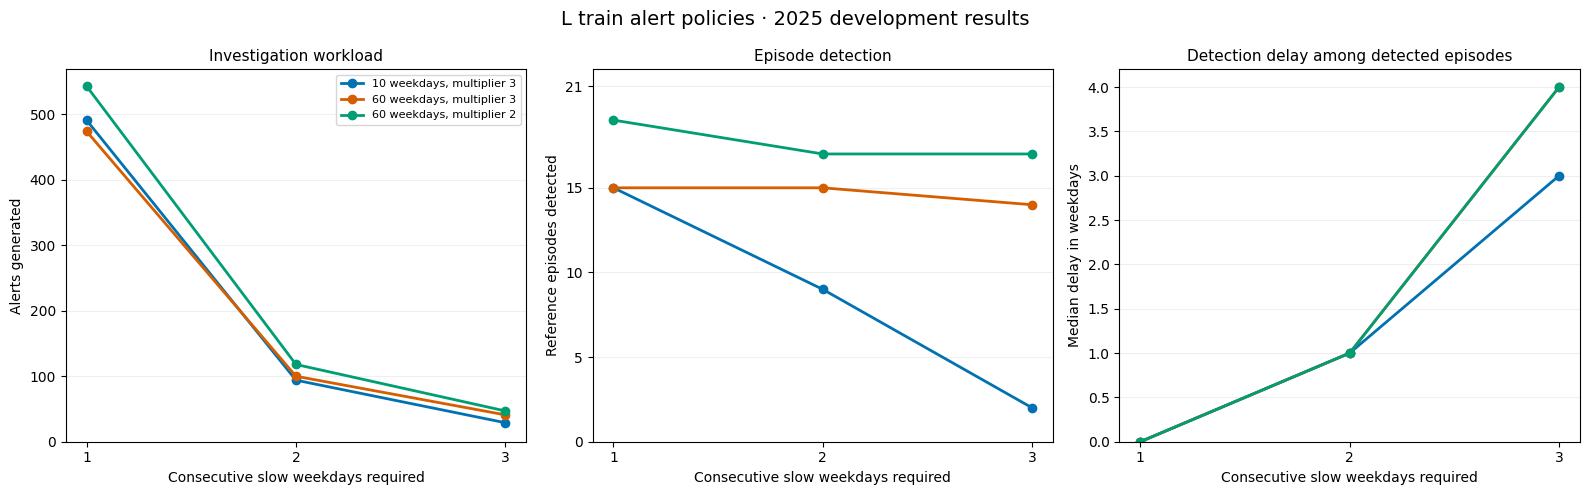

In [5]:
detectors = [
    (10, 3.0, "#0072B2", "10 weekdays, multiplier 3"),
    (60, 3.0, "#D55E00", "60 weekdays, multiplier 3"),
    (60, 2.0, "#009E73", "60 weekdays, multiplier 2"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

panels = [
    ("total_alerts", "Investigation workload", "Alerts generated"),
    ("detected_episodes", "Episode detection", "Reference episodes detected"),
    (
        "median_delay_weekdays",
        "Detection delay among detected episodes",
        "Median delay in weekdays",
    ),
]

for window, multiplier, color, label in detectors:
    results = comparison.loc[
        (comparison["baseline_window_weekdays"] == window)
        & (comparison["variation_multiplier"] == multiplier)
    ].sort_values("wait_weekdays")

    for axis, (metric, title, ylabel) in zip(axes, panels):
        axis.plot(
            results["wait_weekdays"],
            results[metric],
            marker="o",
            linewidth=2,
            color=color,
            label=label,
        )

for axis, (_, title, ylabel) in zip(axes, panels):
    axis.set_title(title, fontsize=11)
    axis.set_xlabel("Consecutive slow weekdays required")
    axis.set_ylabel(ylabel)
    axis.set_xticks([1, 2, 3])
    axis.set_ylim(bottom=0)
    axis.grid(axis="y", alpha=0.2)

axes[1].set_ylim(0, 22)
axes[1].set_yticks([0, 5, 10, 15, 21])

axes[0].legend(fontsize=8)

fig.suptitle(
    "L train alert policies · 2025 development results",
    fontsize=14,
)

fig.tight_layout()
plt.show()

### Measuring additional delay on the same episodes

Compare each waiting policy with a shorter waiting policy for the same detector.

Calculate additional detection delay only for episodes both policies caught.
Separately count episodes lost when the waiting requirement increases.

This avoids interpreting differences between group medians as the delay added to individual episodes.

In [6]:
episode_keys = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "a_stop",
    "b_stop",
    "episode_number",
]

paired_summaries = []

for shorter_wait, longer_wait in [(1, 2), (2, 3), (1, 3)]:
    shorter = episode_scores.loc[
        episode_scores["wait_weekdays"] == shorter_wait,
        episode_keys + ["detected", "detection_delay_weekdays"],
    ].rename(
        columns={
            "detected": "shorter_detected",
            "detection_delay_weekdays": "shorter_delay",
        }
    )

    longer = episode_scores.loc[
        episode_scores["wait_weekdays"] == longer_wait,
        episode_keys + ["detected", "detection_delay_weekdays"],
    ].rename(
        columns={
            "detected": "longer_detected",
            "detection_delay_weekdays": "longer_delay",
        }
    )

    paired = shorter.merge(
        longer,
        on=episode_keys,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    if not paired["_merge"].eq("both").all():
        raise ValueError("The policies were assessed against different episodes.")

    paired["caught_by_both"] = (
        paired["shorter_detected"] & paired["longer_detected"]
    )

    paired["lost_episodes"] = (
        paired["shorter_detected"] & ~paired["longer_detected"]
    )

    paired["newly_detected_episodes"] = (
        ~paired["shorter_detected"] & paired["longer_detected"]
    )

    paired["additional_delay"] = (
        paired["longer_delay"] - paired["shorter_delay"]
    ).where(paired["caught_by_both"])

    summary = paired.groupby(
        ["baseline_window_weekdays", "variation_multiplier"]
    ).agg(
        reference_episodes=("episode_number", "size"),
        caught_by_both=("caught_by_both", "sum"),
        lost_episodes=("lost_episodes", "sum"),
        newly_detected_episodes=("newly_detected_episodes", "sum"),
        median_additional_delay=("additional_delay", "median"),
        maximum_additional_delay=("additional_delay", "max"),
    ).reset_index()

    summary["shorter_wait"] = shorter_wait
    summary["longer_wait"] = longer_wait
    paired_summaries.append(summary)

paired_comparison = pd.concat(paired_summaries, ignore_index=True)

display(
    paired_comparison[
        [
            "baseline_window_weekdays",
            "variation_multiplier",
            "shorter_wait",
            "longer_wait",
            "reference_episodes",
            "caught_by_both",
            "lost_episodes",
            "newly_detected_episodes",
            "median_additional_delay",
            "maximum_additional_delay",
        ]
    ]
)

,baseline_window_weekdays,variation_multiplier,shorter_wait,longer_wait,reference_episodes,caught_by_both,lost_episodes,newly_detected_episodes,median_additional_delay,maximum_additional_delay
0,10,3.0,1,2,21,9,6,0,1.0,3.0
1,60,2.0,1,2,21,17,2,0,1.0,4.0
2,60,3.0,1,2,21,15,0,0,1.0,4.0
3,10,3.0,2,3,21,2,7,0,1.0,1.0
4,60,2.0,2,3,21,17,0,0,1.0,5.0
5,60,3.0,2,3,21,14,1,0,1.0,4.0
6,10,3.0,1,3,21,2,13,0,3.0,4.0
7,60,2.0,1,3,21,17,2,0,4.0,6.0
8,60,3.0,1,3,21,14,1,0,4.0,5.0


### Additional delay for the same episodes

With 60 weekdays of history and multiplier 3, requiring two consecutive slow
weekdays reduced alerts from 474 to 100 while retaining detection of the same
15 reference episodes. Additional detection delay had a median of one weekday
and a maximum of four weekdays.

With 60 weekdays and multiplier 2, increasing the requirement from two to three
weekdays reduced alerts from 118 to 47 and retained the same 17 detections.
Median additional delay was one weekday, with a maximum of five weekdays.

These results quantify the workload and timeliness tradeoff. The maximum
delays show that the typical delay does not describe every episode.

### Checking sensitivity to the episode reference

The current episode reference uses 60 weekdays of history. To examine how
much that choice affects the results, repeat the episode calculation using
20 weekdays while keeping the other rules fixed.

First reproduce the existing SQL episodes in Python. Then assess the same
alerts against the alternative episodes.

In [7]:
with engine.connect() as connection:
    reference_inputs = pd.read_sql_query(
        text("""
            SELECT
                service_date,
                a_stop,
                b_stop,
                a_station,
                b_station,
                direction,
                baseline_window_weekdays,
                travel_seconds,
                baseline_seconds
            FROM public.l_train_development_baseline_cache
            WHERE baseline_window_weekdays IN (20, 60)
            ORDER BY
                baseline_window_weekdays,
                a_stop,
                b_stop,
                service_date
        """),
        connection,
        parse_dates=["service_date"],
    )

    sql_reference_episodes = pd.read_sql_query(
        text("""
            SELECT *
            FROM public.l_train_development_episodes_cache
        """),
        connection,
        parse_dates=["episode_start", "episode_end"],
    )

print(f"Loaded {len(reference_inputs):,} daily reference candidates")
print(f"Loaded {len(sql_reference_episodes)} existing SQL episodes")

Loaded 22,968 daily reference candidates
Loaded 21 existing SQL episodes


In [8]:
def build_reference_episodes(reference_data, history_weekdays):
    days = reference_data.loc[
        reference_data["baseline_window_weekdays"] == history_weekdays
    ].copy()

    known = (
        days["travel_seconds"].notna()
        & days["baseline_seconds"].notna()
    )

    days["reference_slow_day"] = (
        (days["travel_seconds"] - days["baseline_seconds"])
        .ge(10)
        .astype("boolean")
        .mask(~known)
    )

    episode_rows = []

    for (a_stop, b_stop), segment in days.groupby(["a_stop", "b_stop"]):
        segment = (
            segment.sort_values("service_date")
            .reset_index(drop=True)
        )

        flags = segment["reference_slow_day"]

        # Each row describes that weekday and the six following weekdays.
        known_counts = (
            flags.notna()
            .astype(int)
            .rolling(7, min_periods=7)
            .sum()
            .shift(-6)
        )

        slow_counts = (
            flags.fillna(False)
            .astype(int)
            .rolling(7, min_periods=7)
            .sum()
            .shift(-6)
        )

        qualifying = known_counts.eq(7) & slow_counts.ge(5)
        merged_intervals = []

        for position in segment.index[qualifying]:
            window = segment.iloc[position:position + 7]

            slow_dates = window.loc[
                window["reference_slow_day"].fillna(False),
                "service_date",
            ]

            start = slow_dates.min()
            end = slow_dates.max()

            # Merge overlapping intervals for the same directional stretch.
            if (
                merged_intervals
                and start <= merged_intervals[-1]["episode_end"]
            ):
                current = merged_intervals[-1]
                current["episode_end"] = max(current["episode_end"], end)
                current["qualifying_windows"] += 1
            else:
                merged_intervals.append(
                    {
                        "episode_start": start,
                        "episode_end": end,
                        "qualifying_windows": 1,
                    }
                )

        for episode_number, interval in enumerate(merged_intervals, start=1):
            episode_days = segment.loc[
                segment["service_date"].between(
                    interval["episode_start"],
                    interval["episode_end"],
                )
            ]

            episode_rows.append(
                {
                    "a_stop": a_stop,
                    "b_stop": b_stop,
                    "episode_number": episode_number,
                    "episode_start": interval["episode_start"],
                    "episode_end": interval["episode_end"],
                    "qualifying_windows": interval["qualifying_windows"],
                    "episode_weekdays": len(episode_days),
                    "reference_slow_days": int(
                        episode_days["reference_slow_day"].sum()
                    ),
                }
            )

    return pd.DataFrame(
        episode_rows,
        columns=[
            "a_stop",
            "b_stop",
            "episode_number",
            "episode_start",
            "episode_end",
            "qualifying_windows",
            "episode_weekdays",
            "reference_slow_days",
        ],
    )

In [9]:
episodes_60 = build_reference_episodes(reference_inputs, 60)

verification_columns = [
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
    "qualifying_windows",
    "episode_weekdays",
    "reference_slow_days",
]

verification = sql_reference_episodes[verification_columns].merge(
    episodes_60[verification_columns],
    on=verification_columns,
    how="outer",
    indicator=True,
    validate="one_to_one",
)

differences = verification.loc[verification["_merge"] != "both"]

if not differences.empty:
    display(differences)
    raise ValueError("Python episodes differ from SQL. Investigate before continuing.")

print(f"Verified: Python reproduces all {len(episodes_60)} SQL episodes")

# Change only the historical reference window
episodes_20 = build_reference_episodes(reference_inputs, 20)

reference_summaries = []

for window, episodes in [(60, episodes_60), (20, episodes_20)]:
    reference_summaries.append(
        {
            "reference_history_weekdays": window,
            "qualifying_windows": int(episodes["qualifying_windows"].sum()),
            "sustained_episodes": len(episodes),
            "affected_pairs": len(
                episodes[["a_stop", "b_stop"]].drop_duplicates()
            ),
            "mean_episode_weekdays": episodes["episode_weekdays"].mean(),
            "longest_episode_weekdays": episodes["episode_weekdays"].max(),
        }
    )

reference_comparison = pd.DataFrame(reference_summaries)

display(reference_comparison.round(1))

Verified: Python reproduces all 21 SQL episodes


,reference_history_weekdays,qualifying_windows,sustained_episodes,affected_pairs,mean_episode_weekdays,longest_episode_weekdays
0,60,91,21,10,9.2,35
1,20,51,14,11,8.6,17


### Reference definitions produce different episodes

Using 20 weekdays of history produced 14 sustained episodes, compared with
21 using 60 weekdays. The longest episode decreased from 35 to 17 weekdays,
while the number of affected stretches increased from 10 to 11.

The reference choice changes both episode boundaries and which stretches
qualify. Next, assess the same alerts against both references to determine
whether the policy comparison depends on this choice.

In [10]:
def score_reference_episodes(episodes, alert_data, weekday_dates):
    results = []

    configuration_columns = [
        "baseline_window_weekdays",
        "variation_multiplier",
        "wait_weekdays",
    ]

    for configuration, configuration_alerts in alert_data.groupby(
        configuration_columns
    ):
        window, multiplier, wait = configuration

        for episode in episodes.itertuples(index=False):
            matching_alerts = configuration_alerts.loc[
                (configuration_alerts["a_stop"] == episode.a_stop)
                & (configuration_alerts["b_stop"] == episode.b_stop)
                & (
                    configuration_alerts["alert_date"]
                    <= episode.episode_end
                )
                & (
                    configuration_alerts["active_end"]
                    >= episode.episode_start
                )
            ]

            if matching_alerts.empty:
                detection_date = pd.NaT
                delay = None
            else:
                # An alert already active at onset gives zero delay.
                detection_date = matching_alerts["alert_date"].clip(
                    lower=episode.episode_start
                ).min()

                delay = int(
                    (
                        (weekday_dates >= episode.episode_start)
                        & (weekday_dates < detection_date)
                    ).sum()
                )

            results.append(
                {
                    "baseline_window_weekdays": window,
                    "variation_multiplier": multiplier,
                    "wait_weekdays": wait,
                    "a_stop": episode.a_stop,
                    "b_stop": episode.b_stop,
                    "episode_start": episode.episode_start,
                    "episode_end": episode.episode_end,
                    "detected": pd.notna(detection_date),
                    "detection_delay_weekdays": delay,
                }
            )

    return pd.DataFrame(results)


weekday_dates = (
    reference_inputs["service_date"]
    .drop_duplicates()
    .sort_values()
)

scores_60 = score_reference_episodes(episodes_60, alerts, weekday_dates)
scores_20 = score_reference_episodes(episodes_20, alerts, weekday_dates)

# Verify that Python also reproduces the original SQL episode scores.
match_columns = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "wait_weekdays",
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
]

score_verification = scores_60.merge(
    episode_scores[
        match_columns + ["detected", "detection_delay_weekdays"]
    ],
    on=match_columns,
    how="outer",
    suffixes=("_python", "_sql"),
    indicator=True,
    validate="one_to_one",
)

matching_results = (
    score_verification["_merge"].eq("both")
    & score_verification["detected_python"].eq(
        score_verification["detected_sql"]
    )
    & score_verification["detection_delay_weekdays_python"].fillna(-1).eq(
        score_verification["detection_delay_weekdays_sql"].fillna(-1)
    )
)

if not matching_results.all():
    display(score_verification.loc[~matching_results])
    raise ValueError("Python episode scores differ from SQL.")

print("Verified: Python reproduces all 189 SQL episode assessments")

reference_scores = pd.concat(
    [
        scores_60.assign(reference_history_weekdays=60),
        scores_20.assign(reference_history_weekdays=20),
    ],
    ignore_index=True,
)

reference_performance = (
    reference_scores.groupby(
        [
            "reference_history_weekdays",
            "baseline_window_weekdays",
            "variation_multiplier",
            "wait_weekdays",
        ]
    )
    .agg(
        reference_episodes=("detected", "size"),
        detected_episodes=("detected", "sum"),
        median_delay_weekdays=("detection_delay_weekdays", "median"),
    )
    .reset_index()
)

reference_performance["missed_episodes"] = (
    reference_performance["reference_episodes"]
    - reference_performance["detected_episodes"]
)

reference_performance["detected_pct"] = (
    100
    * reference_performance["detected_episodes"]
    / reference_performance["reference_episodes"]
).round(2)

display(reference_performance)

Verified: Python reproduces all 189 SQL episode assessments


,reference_history_weekdays,baseline_window_weekdays,variation_multiplier,wait_weekdays,reference_episodes,detected_episodes,median_delay_weekdays,missed_episodes,detected_pct
0,20,10,3.0,1,14,9,0.0,5,64.29
1,20,10,3.0,2,14,6,1.0,8,42.86
2,20,10,3.0,3,14,1,4.0,13,7.14
3,20,60,2.0,1,14,9,0.0,5,64.29
4,20,60,2.0,2,14,7,3.0,7,50.00
5,20,60,2.0,3,14,6,5.0,8,42.86
6,20,60,3.0,1,14,7,0.0,7,50.00
7,20,60,3.0,2,14,6,3.0,8,42.86
8,20,60,3.0,3,14,5,5.0,9,35.71
9,60,10,3.0,1,21,15,0.0,6,71.43


### The conclusion depends on the reference definition

Alert workload is unchanged when the episode reference changes, but measured
detection performance changes substantially.

For the detector using 60 weekdays and multiplier 3, requiring two slow weekdays
reduced alerts from 474 to 100. It preserved 15 episode detections under the
reference using 60 weekdays, but reduced detections from seven to six under
the reference using 20 weekdays.

The workload reduction is consistent across references. Preserving episode
detection is conditional on the reference definition.

### Comparing investigation effort and undetected slowdown time

Investigation workload is measured by alert count. An illustrative assumption
of five minutes per alert converts that count into investigation hours.

Undetected episode weekdays measure time before detection within each reference
episode. A missed episode contributes its entire duration.

Compare policies separately under each reference definition.

In [11]:
configuration_columns = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "wait_weekdays",
]

reference_columns = [
    "reference_history_weekdays",
    *configuration_columns,
]

# Bring in episode durations under each reference definition
episode_definitions = pd.concat(
    [
        episodes_60.assign(reference_history_weekdays=60),
        episodes_20.assign(reference_history_weekdays=20),
    ],
    ignore_index=True,
)

episode_keys = [
    "reference_history_weekdays",
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
]

episode_cost_inputs = reference_scores.merge(
    episode_definitions[episode_keys + ["episode_weekdays"]],
    on=episode_keys,
    how="left",
    validate="many_to_one",
)

if episode_cost_inputs["episode_weekdays"].isna().any():
    raise ValueError("Some episode scores have no matching duration.")

# Detected episodes contribute their detection delay.
# Missed episodes contribute their full duration
episode_cost_inputs["undetected_episode_weekdays"] = (
    episode_cost_inputs["detection_delay_weekdays"]
    .where(
        episode_cost_inputs["detected"],
        episode_cost_inputs["episode_weekdays"],
    )
    .astype(int)
)

episode_cost_inputs["missed_episode"] = ~episode_cost_inputs["detected"]

decision_results = (
    episode_cost_inputs.groupby(reference_columns)
    .agg(
        reference_episodes=("detected", "size"),
        detected_episodes=("detected", "sum"),
        missed_episodes=("missed_episode", "sum"),
        undetected_episode_weekdays=("undetected_episode_weekdays", "sum"),
    )
    .reset_index()
)

alert_totals = (
    alerts.groupby(configuration_columns)
    .size()
    .rename("total_alerts")
    .reset_index()
)

decision_results = decision_results.merge(
    alert_totals,
    on=configuration_columns,
    validate="many_to_one",
)

minutes_per_alert = 5

decision_results["estimated_investigation_hours"] = (
    decision_results["total_alerts"] * minutes_per_alert / 60
).round(2)

display(
    decision_results[
        reference_columns
        + [
            "total_alerts",
            "estimated_investigation_hours",
            "detected_episodes",
            "missed_episodes",
            "undetected_episode_weekdays",
        ]
    ]
)

,reference_history_weekdays,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,estimated_investigation_hours,detected_episodes,missed_episodes,undetected_episode_weekdays
0,20,10,3.0,1,491,40.92,9,5,43
1,20,10,3.0,2,94,7.83,6,8,79
2,20,10,3.0,3,29,2.42,1,13,117
3,20,60,2.0,1,543,45.25,9,5,43
4,20,60,2.0,2,118,9.83,7,7,66
5,20,60,2.0,3,47,3.92,6,8,92
6,20,60,3.0,1,474,39.50,7,7,54
7,20,60,3.0,2,100,8.33,6,8,77
8,20,60,3.0,3,41,3.42,5,9,96
9,60,10,3.0,1,491,40.92,15,6,46


In [12]:
cost_assumptions = pd.DataFrame(
    {
        "cost_per_undetected_episode_weekday": [1, 5, 10, 25, 50]
    }
)

cost_scenarios = decision_results.merge(cost_assumptions, how="cross")

cost_scenarios["scenario_cost"] = (
    cost_scenarios["total_alerts"]
    + cost_scenarios["cost_per_undetected_episode_weekday"]
    * cost_scenarios["undetected_episode_weekdays"]
)

scenario_groups = [
    "reference_history_weekdays",
    "cost_per_undetected_episode_weekday",
]

lowest_cost = cost_scenarios.groupby(scenario_groups)[
    "scenario_cost"
].transform("min")

preferred_policies = cost_scenarios.loc[
    cost_scenarios["scenario_cost"].eq(lowest_cost)
].sort_values(scenario_groups + configuration_columns)

display(
    preferred_policies[
        scenario_groups
        + configuration_columns
        + [
            "total_alerts",
            "missed_episodes",
            "undetected_episode_weekdays",
            "scenario_cost",
        ]
    ]
)

,reference_history_weekdays,cost_per_undetected_episode_weekday,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,missed_episodes,undetected_episode_weekdays,scenario_cost
40,20,1,60,3.0,3,41,9,96,137
21,20,5,60,2.0,2,118,7,66,448
22,20,10,60,2.0,2,118,7,66,778
3,20,25,10,3.0,1,491,5,43,1566
4,20,50,10,3.0,1,491,5,43,2641
70,60,1,60,2.0,3,47,4,92,139
66,60,5,60,2.0,2,118,4,62,428
62,60,10,60,2.0,1,543,2,14,683
63,60,25,60,2.0,1,543,2,14,893
64,60,50,60,2.0,1,543,2,14,1243


### The preferred policy depends on operational priorities

When undetected episode time has a low assumed cost, policies requiring three
slow weekdays are preferred because they generate fewer alerts.

When one undetected episode weekday costs the equivalent of investigating five
alerts, both reference definitions prefer 60 weekdays of history, multiplier 2,
and two consecutive slow weekdays.

Higher assumed costs favor immediate alerts. The recommendation therefore
depends on how the organization values investigation workload relative to
undetected slowdown time.

Investigation hours assume five minutes per alert.

### Evaluating the frozen method on reserved dates

Apply the existing detector configurations and waiting policies to
January–April 2026. Compare results under both episode references.

Baselines can use earlier history, but each day's alert uses only information
available by that day. Episode labels are established retrospectively.

In [13]:
with engine.connect() as connection:
    development_candidates = pd.read_sql_query(
        text("""
            SELECT *
            FROM public.l_train_development_baseline_cache
        """),
        connection,
        parse_dates=["service_date"],
    )

    evaluation_candidates = pd.read_sql_query(
        text("""
            SELECT *
            FROM public.l_train_baseline_candidates
            WHERE analysis_period = 'evaluation'
            ORDER BY a_stop, b_stop, service_date, baseline_window_weekdays
        """),
        connection,
        parse_dates=["service_date"],
    )

print(f"Loaded {len(evaluation_candidates):,} evaluation candidate rows")

Loaded 11,352 evaluation candidate rows


In [14]:
configuration_columns = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "wait_weekdays",
]

configuration_grid = pd.DataFrame(
    [
        (window, multiplier, wait)
        for window, multiplier in [(10, 3.0), (60, 3.0), (60, 2.0)]
        for wait in [1, 2, 3]
    ],
    columns=configuration_columns,
)


def build_policy_alerts(candidate_days):
    detectors = configuration_grid[
        ["baseline_window_weekdays", "variation_multiplier"]
    ].drop_duplicates()

    days = candidate_days.merge(
        detectors,
        on="baseline_window_weekdays",
        how="inner",
    )

    detector_keys = [
        "baseline_window_weekdays",
        "variation_multiplier",
        "a_stop",
        "b_stop",
    ]

    days = days.sort_values(
        detector_keys + ["service_date"]
    ).reset_index(drop=True)

    days["threshold_seconds"] = (
        days["variation_multiplier"] * 1.4826 * days["mad_seconds"]
    ).clip(lower=10.0)

    known = (
        days["travel_seconds"].notna()
        & days["baseline_seconds"].notna()
        & days["threshold_seconds"].notna()
    )

    days["is_slow_day"] = (
        (days["travel_seconds"] - days["baseline_seconds"])
        .ge(days["threshold_seconds"])
        .astype("boolean")
        .mask(~known)
    )

    # Index every weekday, including unknown observations
    days["weekday_index"] = days.groupby(detector_keys).cumcount() + 1

    # Normal and unknown days separate slow streaks.
    days["break_day"] = (
        ~days["is_slow_day"].fillna(False)
    ).astype(int)

    days["streak_group"] = days.groupby(detector_keys)[
        "break_day"
    ].cumsum()

    slow = days.loc[days["is_slow_day"].fillna(False)].copy()
    streak_keys = detector_keys + ["streak_group"]
    streaks = slow.groupby(streak_keys)

    slow["streak_position"] = streaks.cumcount() + 1
    slow["streak_start"] = streaks["service_date"].transform("min")
    slow["active_end"] = streaks["service_date"].transform("max")
    slow["slow_streak_weekdays"] = streaks["service_date"].transform("size")

    policy_alerts = []

    for wait in [1, 2, 3]:
        selected = slow.loc[slow["streak_position"] == wait].copy()
        selected["wait_weekdays"] = wait
        selected = selected.rename(columns={"service_date": "alert_date"})
        policy_alerts.append(selected)

    return pd.concat(policy_alerts, ignore_index=True)[
        configuration_columns
        + [
            "a_stop",
            "b_stop",
            "streak_start",
            "active_end",
            "alert_date",
            "slow_streak_weekdays",
        ]
    ]


python_development_alerts = build_policy_alerts(development_candidates)

# Check that the Python alert dates and active intervals match SQL.
alert_match_columns = configuration_columns + [
    "a_stop",
    "b_stop",
    "streak_start",
    "alert_date",
    "active_end",
    "slow_streak_weekdays",
]

alert_verification = python_development_alerts[alert_match_columns].merge(
    alerts[alert_match_columns],
    on=alert_match_columns,
    how="outer",
    indicator=True,
    validate="one_to_one",
)

alert_differences = alert_verification.loc[
    alert_verification["_merge"] != "both"
]

if not alert_differences.empty:
    display(alert_differences)
    raise ValueError("Python alerts differ from the development SQL results.")

print(
    f"Verified: Python reproduces all "
    f"{len(python_development_alerts):,} development alerts"
)

evaluation_alerts = build_policy_alerts(evaluation_candidates)

print(f"Generated {len(evaluation_alerts):,} evaluation alert records")

Verified: Python reproduces all 1,937 development alerts
Generated 872 evaluation alert records


In [15]:
evaluation_weekdays = (
    evaluation_candidates["service_date"]
    .drop_duplicates()
    .sort_values()
)

evaluation_episodes = {}
evaluation_score_frames = []

score_columns = configuration_columns + [
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
    "detected",
    "detection_delay_weekdays",
]

for reference_window in [20, 60]:
    episodes = build_reference_episodes(
        evaluation_candidates,
        reference_window,
    )

    evaluation_episodes[reference_window] = episodes

    scores = score_reference_episodes(
        episodes,
        evaluation_alerts,
        evaluation_weekdays,
    ).reindex(columns=score_columns)

    scores["reference_history_weekdays"] = reference_window
    evaluation_score_frames.append(scores)

    print(
        f"Reference using {reference_window} weekdays: "
        f"{len(episodes)} episodes"
    )

evaluation_reference_scores = pd.concat(
    evaluation_score_frames,
    ignore_index=True,
)

evaluation_reference_scores["detected"] = (
    evaluation_reference_scores["detected"].astype(bool)
)

evaluation_reference_scores["detection_delay_weekdays"] = pd.to_numeric(
    evaluation_reference_scores["detection_delay_weekdays"]
)

reference_columns = [
    "reference_history_weekdays",
    *configuration_columns,
]

episode_metrics = (
    evaluation_reference_scores.groupby(reference_columns)
    .agg(
        detected_episodes=("detected", "sum"),
        median_delay_weekdays=("detection_delay_weekdays", "median"),
    )
    .reset_index()
)

reference_counts = pd.DataFrame(
    [
        {
            "reference_history_weekdays": window,
            "reference_episodes": len(episodes),
        }
        for window, episodes in evaluation_episodes.items()
    ]
)

evaluation_performance = (
    reference_counts.merge(configuration_grid, how="cross")
    .merge(
        episode_metrics,
        on=reference_columns,
        how="left",
        validate="one_to_one",
    )
)

evaluation_performance["detected_episodes"] = (
    evaluation_performance["detected_episodes"].fillna(0).astype(int)
)

evaluation_performance["missed_episodes"] = (
    evaluation_performance["reference_episodes"]
    - evaluation_performance["detected_episodes"]
)

evaluation_performance["detected_pct"] = (
    100
    * evaluation_performance["detected_episodes"]
    / evaluation_performance["reference_episodes"].where(
        evaluation_performance["reference_episodes"] > 0
    )
).round(2)

evaluation_alert_totals = (
    evaluation_alerts.groupby(configuration_columns)
    .size()
    .rename("total_alerts")
    .reset_index()
)

evaluation_performance = evaluation_performance.merge(
    evaluation_alert_totals,
    on=configuration_columns,
    how="left",
    validate="many_to_one",
)

evaluation_performance["total_alerts"] = (
    evaluation_performance["total_alerts"].fillna(0).astype(int)
)

display(
    evaluation_performance[
        reference_columns
        + [
            "total_alerts",
            "reference_episodes",
            "detected_episodes",
            "missed_episodes",
            "detected_pct",
            "median_delay_weekdays",
        ]
    ]
)

Reference using 20 weekdays: 13 episodes
Reference using 60 weekdays: 14 episodes


,reference_history_weekdays,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,reference_episodes,detected_episodes,missed_episodes,detected_pct,median_delay_weekdays
0,20,10,3.0,1,217,13,11,2,84.62,0.0
1,20,10,3.0,2,39,13,10,3,76.92,3.0
2,20,10,3.0,3,19,13,9,4,69.23,4.0
3,20,60,3.0,1,222,13,10,3,76.92,0.0
4,20,60,3.0,2,49,13,10,3,76.92,2.0
5,20,60,3.0,3,18,13,8,5,61.54,3.0
6,20,60,2.0,1,235,13,12,1,92.31,0.0
7,20,60,2.0,2,52,13,11,2,84.62,2.0
8,20,60,2.0,3,21,13,9,4,69.23,4.0
9,60,10,3.0,1,217,14,13,1,92.86,0.0


### Results on reserved dates

During January–April 2026, the detector using 60 weekdays and multiplier 2
generated 235 alerts when reacting after only one slow weekday. Requiring two
consecutive slow weekdays reduced this to 52, approximately 78% fewer alerts.

That policy detected 11 of 13 reference episodes using 20 weekdays of history
and 13 of 14 using 60 weekdays. It missed one additional episode under either
reference compared with immediate alerts. Median detection delay among
detected episodes was two weekdays.

With the same waiting requirement, multiplier 2 generated three more alerts
than multiplier 3 and detected one additional episode under each reference.
The reserved results support a substantial workload reduction, with explicit
costs in missed episodes and later detection. 

Overall we learned that we can send far fewer alerts while still catching most 
sustained slowdowns, but we’ll catch some later and miss a few. So we need to evaluate 
the exact tradeoffs and needs of the city.

### Final evaluation of workload and detection costs

Measure additional delay for the same episodes, then apply the cost scenarios
established during development.

Include the full observed duration of missed episodes when counting undetected
time. Investigation effort and relative costs remain explicit assumptions.

The recommendation is conditional on operational priorities and whatever the city needs.

In [16]:
configuration_columns = [
    "baseline_window_weekdays",
    "variation_multiplier",
    "wait_weekdays",
]

detector_columns = [
    "reference_history_weekdays",
    "baseline_window_weekdays",
    "variation_multiplier",
]

episode_keys = detector_columns + [
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
]

paired_summaries = []

for shorter_wait, longer_wait in [(1, 2), (2, 3), (1, 3)]:
    shorter = evaluation_reference_scores.loc[
        evaluation_reference_scores["wait_weekdays"] == shorter_wait,
        episode_keys + ["detected", "detection_delay_weekdays"],
    ].rename(
        columns={
            "detected": "shorter_detected",
            "detection_delay_weekdays": "shorter_delay",
        }
    )

    longer = evaluation_reference_scores.loc[
        evaluation_reference_scores["wait_weekdays"] == longer_wait,
        episode_keys + ["detected", "detection_delay_weekdays"],
    ].rename(
        columns={
            "detected": "longer_detected",
            "detection_delay_weekdays": "longer_delay",
        }
    )

    paired = shorter.merge(
        longer,
        on=episode_keys,
        how="outer",
        indicator=True,
        validate="one_to_one",
    )

    if not paired["_merge"].eq("both").all():
        raise ValueError("The policies were assessed against different episodes.")

    paired["caught_by_both"] = (
        paired["shorter_detected"] & paired["longer_detected"]
    )

    paired["lost_episodes"] = (
        paired["shorter_detected"] & ~paired["longer_detected"]
    )

    paired["newly_detected_episodes"] = (
        ~paired["shorter_detected"] & paired["longer_detected"]
    )

    paired["additional_delay"] = (
        paired["longer_delay"] - paired["shorter_delay"]
    ).where(paired["caught_by_both"])

    if paired["newly_detected_episodes"].any():
        raise ValueError("A longer waiting policy unexpectedly gained an episode.")

    if paired["additional_delay"].dropna().lt(0).any():
        raise ValueError("A longer waiting policy unexpectedly detected earlier.")

    summary = (
        paired.groupby(detector_columns)
        .agg(
            reference_episodes=("detected_python", "size")
            if "detected_python" in paired.columns
            else ("shorter_detected", "size"),
            caught_by_both=("caught_by_both", "sum"),
            lost_episodes=("lost_episodes", "sum"),
            median_additional_delay=("additional_delay", "median"),
            maximum_additional_delay=("additional_delay", "max"),
        )
        .reset_index()
    )

    summary["shorter_wait"] = shorter_wait
    summary["longer_wait"] = longer_wait
    paired_summaries.append(summary)

evaluation_paired_comparison = pd.concat(
    paired_summaries,
    ignore_index=True,
)

display(
    evaluation_paired_comparison.loc[
        (evaluation_paired_comparison["baseline_window_weekdays"] == 60)
        & (evaluation_paired_comparison["variation_multiplier"] == 2)
    ]
)

,reference_history_weekdays,baseline_window_weekdays,variation_multiplier,reference_episodes,caught_by_both,lost_episodes,median_additional_delay,maximum_additional_delay,shorter_wait,longer_wait
1,20,60,2.0,13,11,1,1.0,4.0,1,2
4,60,60,2.0,14,13,1,1.0,4.0,1,2
7,20,60,2.0,13,9,2,1.0,1.0,2,3
10,60,60,2.0,14,11,2,1.0,1.0,2,3
13,20,60,2.0,13,9,3,4.0,5.0,1,3
16,60,60,2.0,14,11,3,4.0,5.0,1,3


### Additional detection delay on reserved dates

For the detector using 60 weekdays and multiplier 2, requiring two slow weekdays
instead of one loses one episode detection under either reference. Among
episodes both policies detect, additional delay has a median of one weekday
and a maximum of four.

Increasing the requirement from two to three weekdays loses two further
episode detections under either reference. Shared detections occur one
weekday later.

In [ ]:
reference_columns = [
    "reference_history_weekdays",
    *configuration_columns,
]

evaluation_episode_definitions = pd.concat(
    [
        episodes.assign(reference_history_weekdays=window)
        for window, episodes in evaluation_episodes.items()
    ],
    ignore_index=True,
)

episode_match_columns = [
    "reference_history_weekdays",
    "a_stop",
    "b_stop",
    "episode_start",
    "episode_end",
]

evaluation_cost_inputs = evaluation_reference_scores.merge(
    evaluation_episode_definitions[
        episode_match_columns + ["episode_weekdays"]
    ],
    on=episode_match_columns,
    how="left",
    validate="many_to_one",
)

if evaluation_cost_inputs["episode_weekdays"].isna().any():
    raise ValueError("Some episode scores have no matching duration.")


evaluation_cost_inputs["undetected_episode_weekdays"] = (
    evaluation_cost_inputs["detection_delay_weekdays"]
    .where(
        evaluation_cost_inputs["detected"],
        evaluation_cost_inputs["episode_weekdays"],
    )
    .astype(int)
)

undetected_totals = (
    evaluation_cost_inputs.groupby(reference_columns)
    .agg(
        undetected_episode_weekdays=(
            "undetected_episode_weekdays",
            "sum",
        )
    )
    .reset_index()
)

evaluation_decision_results = evaluation_performance.merge(
    undetected_totals,
    on=reference_columns,
    how="left",
    validate="one_to_one",
)

if evaluation_decision_results["undetected_episode_weekdays"].isna().any():
    raise ValueError("Some configurations have no undetected time assessment.")

minutes_per_alert = 5

evaluation_decision_results["estimated_investigation_hours"] = (
    evaluation_decision_results["total_alerts"]
    * minutes_per_alert
    / 60
).round(2)

display(
    evaluation_decision_results[
        reference_columns
        + [
            "total_alerts",
            "estimated_investigation_hours",
            "detected_episodes",
            "missed_episodes",
            "undetected_episode_weekdays",
        ]
    ]
)

,reference_history_weekdays,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,estimated_investigation_hours,detected_episodes,missed_episodes,undetected_episode_weekdays
0,20,10,3.0,1,217,18.08,11,2,16
1,20,10,3.0,2,39,3.25,10,3,41
2,20,10,3.0,3,19,1.58,9,4,53
3,20,60,3.0,1,222,18.50,10,3,19
4,20,60,3.0,2,49,4.08,10,3,40
5,20,60,3.0,3,18,1.50,8,5,56
6,20,60,2.0,1,235,19.58,12,1,12
7,20,60,2.0,2,52,4.33,11,2,37
8,20,60,2.0,3,21,1.75,9,4,54
9,60,10,3.0,1,217,18.08,13,1,11


### Estimated investigation effort

Requiring two slow weekdays reduces alerts from 235 to 52. Assuming five
minutes per investigation, estimated effort falls from 19.58 to 4.33 hours
during the evaluation period.

The workload reduction comes with additional undetected episode time.
Across all reference episodes, this rises from 12 to 37 segment weekdays
under the reference using 20 weekdays, and from 5 to 35 under the reference
using 60 weekdays. These totals include the full observed duration of missed
episodes and are separate from passenger delay.

In [18]:
evaluation_cost_assumptions = pd.DataFrame(
    {
        "cost_per_undetected_episode_weekday": [1, 5, 10, 25, 50]
    }
)

evaluation_cost_scenarios = evaluation_decision_results.merge(
    evaluation_cost_assumptions,
    how="cross",
)

# One alert costs one scenario unit
evaluation_cost_scenarios["scenario_cost"] = (
    evaluation_cost_scenarios["total_alerts"]
    + evaluation_cost_scenarios["cost_per_undetected_episode_weekday"]
    * evaluation_cost_scenarios["undetected_episode_weekdays"]
)

scenario_groups = [
    "reference_history_weekdays",
    "cost_per_undetected_episode_weekday",
]

lowest_cost = evaluation_cost_scenarios.groupby(scenario_groups)[
    "scenario_cost"
].transform("min")

evaluation_preferred_policies = evaluation_cost_scenarios.loc[
    evaluation_cost_scenarios["scenario_cost"].eq(lowest_cost)
].sort_values(scenario_groups + configuration_columns)

display(
    evaluation_preferred_policies[
        scenario_groups
        + configuration_columns
        + [
            "total_alerts",
            "detected_episodes",
            "missed_episodes",
            "undetected_episode_weekdays",
            "scenario_cost",
        ]
    ]
)

,reference_history_weekdays,cost_per_undetected_episode_weekday,baseline_window_weekdays,variation_multiplier,wait_weekdays,total_alerts,detected_episodes,missed_episodes,undetected_episode_weekdays,scenario_cost
10,20,1,10,3.0,3,19,9,4,53,72
36,20,5,60,2.0,2,52,11,2,37,237
32,20,10,60,2.0,1,235,12,1,12,355
33,20,25,60,2.0,1,235,12,1,12,535
34,20,50,60,2.0,1,235,12,1,12,835
70,60,1,60,3.0,3,18,10,4,58,76
81,60,5,60,2.0,2,52,13,1,35,227
77,60,10,60,2.0,1,235,14,0,5,285
78,60,25,60,2.0,1,235,14,0,5,360
79,60,50,60,2.0,1,235,14,0,5,485


In [19]:
from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "sql").is_dir():
    raise ValueError("Check the notebook working directory before exporting.")

export_directory = project_root / "data" / "exports"
export_directory.mkdir(parents=True, exist_ok=True)

exports = {
    "evaluation_policy_results.csv": evaluation_decision_results,
    "evaluation_paired_delays.csv": evaluation_paired_comparison,
    "evaluation_cost_scenarios.csv": evaluation_cost_scenarios,
    "evaluation_preferred_policies.csv": evaluation_preferred_policies,
}

for filename, table in exports.items():
    table.to_csv(export_directory / filename, index=False)
    print(f"Saved {filename}: {len(table):,} rows")

Saved evaluation_policy_results.csv: 18 rows
Saved evaluation_paired_delays.csv: 18 rows
Saved evaluation_cost_scenarios.csv: 90 rows
Saved evaluation_preferred_policies.csv: 10 rows


### Final recommendation

Consider a policy using 60 weekdays of history, variability multiplier 2,
and two consecutive slow weekdays when reducing investigation workload is
a priority.

On the reserved January–April 2026 data, this policy reduced alerts from
235 to 52, approximately 78%, while losing one episode detection under either
reference. Among episodes both policies detected, additional delay had a
median of one weekday and a maximum of four.

This policy was preferred under both references when one undetected episode
weekday was assigned the cost of five investigations. When that assumed cost
increased to ten or more, immediate alerts were preferred.

The recommendation is conditional on operational priorities. Investigation
effort is assumed, the episode references are derived from travel times, and
the evaluation contains only 13 or 14 reference episodes. Stakeholder input
would be needed to choose actual investigation costs and acceptable delays.
